### Notebook 3: YOLO11s comparison, pass/fail and speed
Requires the notebook 2 results in pork_runs and a T4 GPU runtime.

#### 0. Setup

In [ ]:
# Install Ultralytics
%pip install -q ultralytics

In [ ]:
# Mount Google Drive, set paths, and extract dataset if needed
import zipfile
from pathlib import Path

ZIP_PATH = Path("/content/drive/MyDrive/pork_rasher_v4.zip")
DATA_DIR = Path("/content/pork_rasher")
SPLITS_DIR = Path("/content/splits")
RUNS_DIR = Path("/content/drive/MyDrive/pork_runs")

# Mount Google Drive if running in Google Colab
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

# Unzip the dataset if it hasn't been extracted yet
if not (DATA_DIR / "data.yaml").exists():
    if ZIP_PATH.exists():
        print(f"Extracting {ZIP_PATH.name}...")
        DATA_DIR.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
            zip_ref.extractall(DATA_DIR)
    else:
        raise FileNotFoundError(f"Dataset zip file not found at: {ZIP_PATH}")

# Verify outputs from notebook 2 exist
assert (RUNS_DIR / "split_assignment.csv").exists(), "Missing split_assignment.csv: please run notebook 2 first."
assert (RUNS_DIR / "blocked" / "weights" / "best.pt").exists(), "Missing best.pt weight file: please run notebook 2 first."

# Ensure figures output directory exists
(RUNS_DIR / "figures").mkdir(parents=True, exist_ok=True)

Mounted at /content/drive
Extracting pork_rasher_v4.zip...


##### Settings

In [ ]:
# Training, threshold and bootstrap settings
import torch

NEW_MODEL = "yolo11s.pt"
EPOCHS = 50
IMGSZ = 640
BATCH = 16
SEED = 0
MAX_MISS_RATE = 0.05    # max share of bad trays allowed to pass
N_BOOT = 2000           # bootstrap resamples
N_TIMING_IMAGES = 50    # images used for timing

DEVICE = 0 if torch.cuda.is_available() else "cpu"
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (training will be very slow)")

GPU: Tesla T4


#### 1. Rebuild blocked split

In [ ]:
# Rebuild the blocked split folders from split_assignment.csv
import shutil
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import yaml
from PIL import Image
from pathlib import Path

SPLITS = ["train", "valid", "test"]
with open(DATA_DIR / "data.yaml") as f:
    CLASS_NAMES = yaml.safe_load(f)["names"]

assign = pd.read_csv(RUNS_DIR / "split_assignment.csv")
root = SPLITS_DIR / "blocked"
if root.exists():
    shutil.rmtree(root)
for s in SPLITS:
    (root / s / "images").mkdir(parents=True)
    (root / s / "labels").mkdir(parents=True)

for _, r in assign[assign.blocked_split.isin(SPLITS)].iterrows():
    src_img = DATA_DIR / r.original_split / "images" / r.image
    src_label = DATA_DIR / r.original_split / "labels" / (Path(r.image).stem + ".txt")
    shutil.copy(src_img, root / r.blocked_split / "images" / r.image)
    new_label = root / r.blocked_split / "labels" / (Path(r.image).stem + ".txt")
    if src_label.exists():
        shutil.copy(src_label, new_label)
    else:
        new_label.write_text("")

DATA_YAML = root / "data.yaml"
DATA_YAML.write_text(yaml.safe_dump({
    "path": str(root),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": dict(enumerate(CLASS_NAMES))
}, sort_keys=False))

print({s: len(list((root / s / "images").iterdir())) for s in SPLITS})

{'train': 844, 'valid': 204, 'test': 197}


#### 2. Train YOLO11s

In [ ]:
# Train YOLO11s on the blocked split (skipped if best.pt already exists)
# resume an interrupted run: YOLO(str(RUNS_DIR / "blocked_yolo11s" / "weights" / "last.pt")).train(resume=True)
from ultralytics import YOLO

MODELS = {"YOLO11n": RUNS_DIR / "blocked" / "weights" / "best.pt",          # from notebook 2
          "YOLO11s": RUNS_DIR / "blocked_yolo11s" / "weights" / "best.pt"}  # trained here

if MODELS["YOLO11s"].exists():
    print("YOLO11s already trained, skipping")
else:
    YOLO(NEW_MODEL).train(data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
                          device=DEVICE, seed=SEED, deterministic=True,
                          project=str(RUNS_DIR), name="blocked_yolo11s", exist_ok=True, plots=True, verbose=False)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
YOLO11s already trained, skipping


##### Training curves

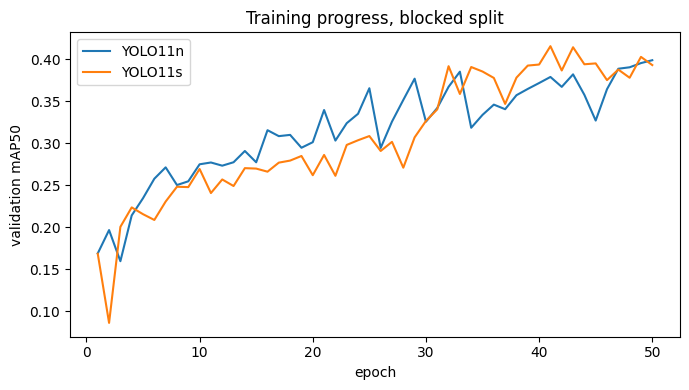

In [ ]:
# validation mAP50 per epoch for both models
plt.figure(figsize=(7, 4))
for name, run in [("YOLO11n", "blocked"), ("YOLO11s", "blocked_yolo11s")]:
    r = pd.read_csv(RUNS_DIR / run / "results.csv")
    r.columns = r.columns.str.strip()
    plt.plot(r["epoch"], r["metrics/mAP50(B)"], label=name)
plt.xlabel("epoch")
plt.ylabel("validation mAP50")
plt.title("Training progress, blocked split")
plt.legend()
plt.tight_layout()
plt.savefig(RUNS_DIR / "figures" / "training_curves_n_vs_s.png", dpi=150)
plt.show()

#### 3. Test scores and model size

In [ ]:
# Test-set metrics, parameter count, GFLOPs and file size for each model
from ultralytics.utils.torch_utils import get_num_params, get_flops

detect_rows = []
per_class = {}
for name, weights in MODELS.items():
    model = YOLO(str(weights))
    m = model.val(data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=BATCH, device=DEVICE,
                  project=str(RUNS_DIR), name="test_" + name, exist_ok=True, plots=True, verbose=False)
    detect_rows.append({"model": name,
                        "params_millions": round(get_num_params(model.model) / 1e6, 2),
                        "GFLOPs": round(get_flops(model.model, IMGSZ), 1),
                        "file_MB": round(weights.stat().st_size / 1e6, 1),
                        "precision": m.box.mp, "recall": m.box.mr, "mAP50": m.box.map50, "mAP50_95": m.box.map})
    per_class[name] = {CLASS_NAMES[c]: ap for c, ap in zip(m.box.ap_class_index, m.box.ap50)}

detect_table = pd.DataFrame(detect_rows).set_index("model").round(3)
per_class_table = pd.DataFrame(per_class).reindex(CLASS_NAMES).round(3)
per_class_table.index.name = "test mAP50 per class"
display(detect_table)
display(per_class_table)

Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,598,023 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1439.6±318.8 MB/s, size: 68.3 KB)
val: Scanning /content/splits/blocked/test/labels... 197 images, 29 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 197/197 1.6Kit/s 0.1s
val: New cache created: /content/splits/blocked/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 13/13 3.7it/s 3.5s
                   all        197        189      0.564      0.367      0.459       0.23
Speed: 2.1ms preprocess, 4.7ms inference, 0.0ms loss, 2.0ms postprocess per image
Results saved to /content/drive/MyDrive/pork_runs/test_YOLO11n
Ultralytics 8.4.188 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11s summary (fused): 100 layers, 9,414,735 parameters, 0 gradients, 21.4 GFLOPs
val: Fast image access

,params_millions,GFLOPs,file_MB,precision,recall,mAP50,mAP50_95
model,,,,,,,
YOLO11n,2.61,6.6,5.5,0.564,0.367,0.459,0.23
YOLO11s,9.43,21.7,19.2,0.702,0.268,0.336,0.18


,YOLO11n,YOLO11s
test mAP50 per class,,
loose-meat,0.361,0.031
packaging-error,0.626,0.576
twisted-meat,0.388,0.163
unsealed,0.919,0.912
wrinkle,0.000,0.000


#### 4. Inference speed

In [ ]:
# Median time per image (batch size 1, after 5 warm-up images) on GPU and CPU
test_images = sorted((root / "test" / "images").iterdir())
timing_images = test_images[:N_TIMING_IMAGES]


def time_model(weights, device):
    model = YOLO(str(weights))
    for p in timing_images[:5]:   # warm up
        model.predict(str(p), imgsz=IMGSZ, device=device, verbose=False)
    times = []
    for p in timing_images:
        if device != "cpu":
            torch.cuda.synchronize()   # wait for the GPU to finish before timing
        start = time.perf_counter()
        model.predict(str(p), imgsz=IMGSZ, device=device, verbose=False)
        if device != "cpu":
            torch.cuda.synchronize()
        times.append((time.perf_counter() - start) * 1000)
    return float(np.median(times))


speed_rows = []
for name, weights in MODELS.items():
    row = {"model": name}
    if torch.cuda.is_available():
        row["GPU_ms_per_image"] = time_model(weights, 0)
    row["CPU_ms_per_image"] = time_model(weights, "cpu")
    speed_rows.append(row)

speed_table = pd.DataFrame(speed_rows).set_index("model")
for col in list(speed_table.columns):
    speed_table[col.replace("_ms_per_image", "_trays_per_second")] = 1000 / speed_table[col]
speed_table = speed_table.round(1)
display(speed_table)

,GPU_ms_per_image,CPU_ms_per_image,GPU_trays_per_second,CPU_trays_per_second
model,,,,
YOLO11n,13.0,88.9,77.1,11.3
YOLO11s,13.4,219.5,74.5,4.6


#### 5. Pass/fail

##### Predictions

In [ ]:
# Highest detection confidence per image for the valid and test sets
def classes_in_label(path):
    if not path.exists():
        return set()
    return {CLASS_NAMES[int(line.split()[0])] for line in path.read_text().splitlines() if line.strip()}


def predict_split(weights, split):
    model = YOLO(str(weights))
    paths = sorted((root / split / "images").iterdir())
    rows = []
    results = model.predict([str(p) for p in paths], conf=0.001, imgsz=IMGSZ, device=DEVICE, stream=True, verbose=False)
    for p, r in zip(paths, results):
        true_classes = classes_in_label(root / split / "labels" / (p.stem + ".txt"))
        confs = r.boxes.conf.cpu().numpy()
        rows.append({"image": p.name, "path": str(p), "is_bad": len(true_classes) > 0,
                     "true_classes": ";".join(sorted(true_classes)),
                     "max_conf": float(confs.max()) if len(confs) > 0 else 0.0})   # 0 = nothing detected
    return pd.DataFrame(rows)


PRED = {}
for name, weights in MODELS.items():
    for split in ["valid", "test"]:
        PRED[(name, split)] = predict_split(weights, split)
        PRED[(name, split)].to_csv(RUNS_DIR / f"passfail_predictions_{name}_{split}.csv", index=False)

for split in ["valid", "test"]:
    d = PRED[("YOLO11n", split)]
    print(f"{split}: {len(d)} trays, {d.is_bad.sum()} bad, {(~d.is_bad).sum()} good")

valid: 204 trays, 154 bad, 50 good
test: 197 trays, 168 bad, 29 good


##### Threshold sweep

In [ ]:
# Pass/fail counts and rates for each threshold
def passfail(df, t):
    fail = df.max_conf.to_numpy() >= t
    bad = df.is_bad.to_numpy()
    caught = int((fail & bad).sum())
    missed = int((~fail & bad).sum())
    false_rejects = int((fail & ~bad).sum())
    correct_passes = int((~fail & ~bad).sum())
    return {"threshold": t, "caught": caught, "missed": missed, "false_rejects": false_rejects,
            "correct_passes": correct_passes,
            "miss_rate": missed / max(caught + missed, 1),
            "false_reject_rate": false_rejects / max(false_rejects + correct_passes, 1),
            "accuracy": (caught + correct_passes) / len(df)}


THRESHOLDS = np.round(np.arange(0.01, 0.96, 0.01), 2)
SWEEP = {key: pd.DataFrame([passfail(df, t) for t in THRESHOLDS]) for key, df in PRED.items()}

#### 6. Threshold selection

YOLO11n: threshold = 0.04
YOLO11s: threshold = 0.03


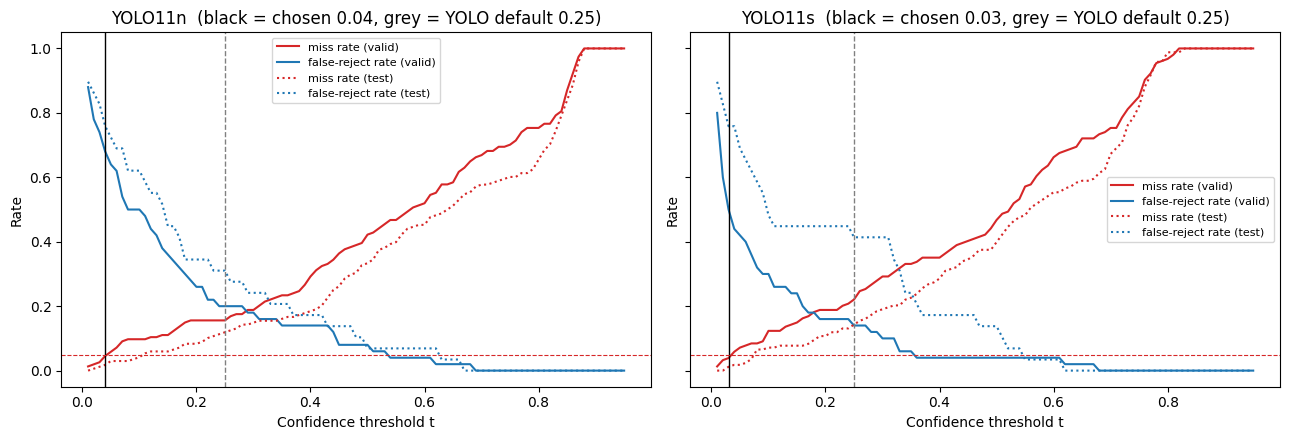

In [ ]:
# Choose the threshold on validation: fewest false rejects with miss rate <= MAX_MISS_RATE
def choose_threshold(sweep):
    ok = sweep[sweep.miss_rate <= MAX_MISS_RATE]
    if len(ok) > 0:
        best = ok.sort_values(["false_reject_rate", "threshold"], ascending=[True, False]).iloc[0]
    else:
        best = sweep.sort_values(["miss_rate", "threshold"], ascending=[True, False]).iloc[0]
    return float(best.threshold), len(ok) > 0


CHOSEN = {}
for name in MODELS:
    t, reached = choose_threshold(SWEEP[(name, "valid")])
    CHOSEN[name] = t
    print(f"{name}: threshold = {t:.2f}" + ("" if reached else " (couldn't reach the miss rate target)"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, name in zip(axes, MODELS):
    for split, style in [("valid", "-"), ("test", ":")]:
        s = SWEEP[(name, split)]
        ax.plot(s.threshold, s.miss_rate, style, color="tab:red", label=f"miss rate ({split})")
        ax.plot(s.threshold, s.false_reject_rate, style, color="tab:blue", label=f"false-reject rate ({split})")
    ax.axvline(CHOSEN[name], color="k", lw=1)
    ax.axvline(0.25, color="grey", lw=1, ls="--")
    ax.axhline(MAX_MISS_RATE, color="tab:red", lw=0.8, ls="--")
    ax.set(title=f"{name}  (black = chosen {CHOSEN[name]:.2f}, grey = YOLO default 0.25)",
           xlabel="Confidence threshold t", ylabel="Rate")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(RUNS_DIR / "figures" / "threshold_sweep.png", dpi=150)
plt.show()

#### 7. Test results with bootstrap intervals

In [ ]:
# Miss and false-reject rates on the test set with 95% bootstrap intervals
def bootstrap_ci(df, t):
    rng = np.random.default_rng(SEED)
    fail = df.max_conf.to_numpy() >= t
    bad = df.is_bad.to_numpy()
    idx = rng.integers(0, len(df), size=(N_BOOT, len(df)))   # bootstrap resample indices
    f = fail[idx]
    b = bad[idx]
    miss = (~f & b).sum(axis=1) / np.maximum(b.sum(axis=1), 1)
    frej = (f & ~b).sum(axis=1) / np.maximum((~b).sum(axis=1), 1)
    return np.percentile(miss, [2.5, 97.5]), np.percentile(frej, [2.5, 97.5])


final_rows = []
for name in MODELS:
    df = PRED[(name, "test")]
    for label, t in [("default 0.25", 0.25), ("chosen on validation", CHOSEN[name])]:
        r = passfail(df, t)
        miss_ci, frej_ci = bootstrap_ci(df, t)
        final_rows.append({"model": name, "threshold": f"{t:.2f} ({label})",
                           "bad_trays_missed": f"{r['missed']} of {r['missed'] + r['caught']}",
                           "miss_rate": f"{r['miss_rate']:.1%}  [{miss_ci[0]:.1%} – {miss_ci[1]:.1%}]",
                           "good_trays_rejected": f"{r['false_rejects']} of {r['false_rejects'] + r['correct_passes']}",
                           "false_reject_rate": f"{r['false_reject_rate']:.1%}  [{frej_ci[0]:.1%} – {frej_ci[1]:.1%}]",
                           "accuracy": f"{r['accuracy']:.1%}"})

final_table = pd.DataFrame(final_rows).set_index(["model", "threshold"])
display(final_table)

bad_trays_missed              miss_rate  \
model   threshold                                                             
YOLO11n 0.25 (default 0.25)                20 of 168  11.9%  [7.1% – 17.1%]   
        0.04 (chosen on validation)         3 of 168    1.8%  [0.0% – 4.2%]   
YOLO11s 0.25 (default 0.25)                24 of 168  14.3%  [9.2% – 19.9%]   
        0.03 (chosen on validation)         2 of 168    1.2%  [0.0% – 3.0%]   

                                    good_trays_rejected  \
model   threshold                                         
YOLO11n 0.25 (default 0.25)                     9 of 29   
        0.04 (chosen on validation)            22 of 29   
YOLO11s 0.25 (default 0.25)                    12 of 29   
        0.03 (chosen on validation)            22 of 29   

                                          false_reject_rate accuracy  
model   threshold                                                     
YOLO11n 0.25 (default 0.25)          31.0%  [14.3% – 48.6%]    85.3%  
        0.04 (chosen on validation)  75.9%  [59.4% – 90.5%]    87.3%  
YOLO11s 0.25 (default 0.25)          41.4%  [24.0% – 60.0%]    81.7%  
        0.03 (chosen on validation)  75.9%  [58.8% – 90.5%]    87.8%

#### 8. Missed defects

In [ ]:
# Number of test trays with each defect, and how many were missed
miss_rows = []
for name in MODELS:
    df = PRED[(name, "test")]
    passed = df.max_conf < CHOSEN[name]
    for c in CLASS_NAMES:
        has_c = df.true_classes.str.split(";").apply(lambda cs: c in cs)
        miss_rows.append({"model": name, "defect": c,
                          "test_trays_with_defect": int(has_c.sum()), "missed": int((has_c & passed).sum())})
miss_table = pd.DataFrame(miss_rows).pivot(index="defect", columns="model", values=["test_trays_with_defect", "missed"])
display(miss_table)

test_trays_with_defect          missed        
model                          YOLO11n YOLO11s YOLO11n YOLO11s
defect                                                        
loose-meat                           4       4       1       0
packaging-error                     74      74       0       1
twisted-meat                         4       4       0       0
unsealed                            92      92       1       0
wrinkle                              1       1       1       1

##### Missed trays

3 missed bad trays


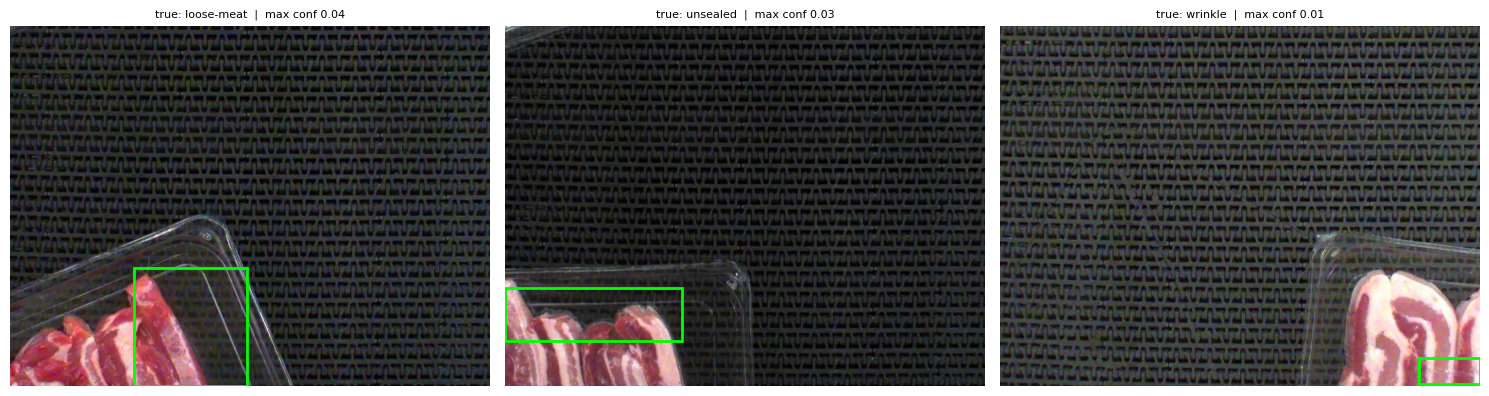

In [ ]:
# Plot missed bad trays: labelled boxes (green) and model detections (red)
SHOW_MODEL = "YOLO11n"   # or "YOLO11s"
df = PRED[(SHOW_MODEL, "test")]
missed = df[df.is_bad & (df.max_conf < CHOSEN[SHOW_MODEL])]
print(len(missed), "missed bad trays")
missed = missed.head(6)

if len(missed) > 0:
    model = YOLO(str(MODELS[SHOW_MODEL]))
    n_rows = int(np.ceil(len(missed) / 3))
    fig, axes = plt.subplots(n_rows, 3, figsize=(15, 4 * n_rows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, (_, r) in zip(axes.flat, missed.iterrows()):
        res = model.predict(r.path, conf=0.05, imgsz=IMGSZ, device=DEVICE, verbose=False)[0]
        ax.imshow(res.plot(line_width=2)[..., ::-1])   # detections, BGR -> RGB
        W, H = Image.open(r.path).size
        label_file = root / "test" / "labels" / (Path(r.path).stem + ".txt")
        for line in label_file.read_text().splitlines():
            _, xc, yc, w, h = [float(v) for v in line.split()]
            ax.add_patch(patches.Rectangle(((xc - w / 2) * W, (yc - h / 2) * H), w * W, h * H,
                                           fill=False, ec="lime", lw=2))
        ax.set_title(f"true: {r.true_classes}  |  max conf {r.max_conf:.2f}", fontsize=8)
    plt.tight_layout()
    plt.savefig(RUNS_DIR / "figures" / f"missed_trays_{SHOW_MODEL}.png", dpi=150)
    plt.show()

#### 9. Summary

In [ ]:
# Summary table, and save results to pork_runs
summary = detect_table[["params_millions", "GFLOPs", "file_MB", "mAP50", "mAP50_95"]].join(speed_table)
for name in MODELS:
    r = passfail(PRED[(name, "test")], CHOSEN[name])
    summary.loc[name, "chosen_threshold"] = CHOSEN[name]
    summary.loc[name, "test_miss_rate"] = round(r["miss_rate"], 3)
    summary.loc[name, "test_false_reject_rate"] = round(r["false_reject_rate"], 3)
display(summary)

summary.to_csv(RUNS_DIR / "model_comparison_summary.csv")
final_table.to_csv(RUNS_DIR / "passfail_test_results.csv")
per_class_table.to_csv(RUNS_DIR / "model_comparison_per_class.csv")
pd.concat({f"{k[0]}_{k[1]}": v for k, v in SWEEP.items()}).to_csv(RUNS_DIR / "threshold_sweep.csv")
print("saved to", RUNS_DIR)

,params_millions,GFLOPs,file_MB,mAP50,mAP50_95,GPU_ms_per_image,CPU_ms_per_image,GPU_trays_per_second,CPU_trays_per_second,chosen_threshold,test_miss_rate,test_false_reject_rate
model,,,,,,,,,,,,
YOLO11n,2.61,6.6,5.5,0.459,0.23,13.0,88.9,77.1,11.3,0.04,0.018,0.759
YOLO11s,9.43,21.7,19.2,0.336,0.18,13.4,219.5,74.5,4.6,0.03,0.012,0.759


saved to /content/drive/MyDrive/pork_runs
